# Chapter 5: Multilayer Perceptrons

In [30]:
import torch
from torch import nn
from d2l import torch as d2l

# 5.1 Multilayer Perceptrons

### 5.1.1 Hidden Layers

* Recall previously in Section 3.1.1.1, affine transformations were described as linear transformation with added bias
* However, typically linearity in affine transformations is a strong assumption that is not garunteed to hold
* While there may exist a representation of our data that accounts for relevant interactions between features where building a linear model on top mayb be suitable, we do not know how to calculate it by hand
* With Deep Neural Networks, we use observational data to jointly learn a representation of the data in the hidden layers and a linear predictor that acts upon said representation
* Easiest way to create hidden layers is by stacking many fully connected layers on each other
    * First $L-1$ layers as our representation, and final layer as linear predictor
* Note that simply blindly stacking fully connected layers doesn't do anything new, as mathematically it is equivalent to a matrix product
* Overcome this with a _nonlinear activation function_ applied to each hidden unit/layer following the affine transformation 
    * Popular choice is the ReLU: $\sigma(x) = \text{max}(0, x)$, which would operate on the arguments in a elementwise fashion
    * Note that the nonlinear activation functions make the MLP no longer collapsable into a simple linear function 
* Results suggest even with a single hidden layer network, given enough nodes and right set of weights, we can model any function (Section 5.1.1.4, Google, YouTube on UAT)
    * Does not mean we should aim to do so, even if theoretically possible
    * We can approximate functions much more compactly by using deeper (rather than wider, single layer) networks

### 5.1.2 Activation Functions
* Rectified Linear Unit (ReLU): $ \text{ReLU}(x) = \text{max}(x, 0)$
    * Piecewise linear
    * Technically not differentiable in strict sense, but we just say derivative is 0 when input is 0. It is possible that the input is never 0
    * Sidenote - old adage about if subtle boundary conditions matter, we are doing real/pure math not engineering
    * Derivative is 0 for inputs of 0 or less than 0, and derivative is 1 for non-negative inputs
    * Notice with standard ReLU's they either let the derivative through or nothing at all
* Parametrisized ReLU: $ \text{pReLU}(x) = \text{max}(0, x) + \alpha \text{min}(0, x)$
    * Adds a lienar term to the ReLU so some information still gets through even when argument is negative
* Sigmoid Function: $\text{sigmoid}(x) = \frac{1}{1+ \exp{(-x)}} $
    * Originally, wanted threshold activation to take 0 or 1 for some threshold
    * When attention shifted to gradient-based learning, focused on sigmoid due to its smooth, differentiable properties
    * Largely replaced by simpler and easily trainable ReLU for most hidden layers since its gradient vanishes for both large and small negative arguments
    * Sigmoid approaches linear transform for inputs close to 0
    * Its derivative approaches 0 as argument moves away from 0 
* Tanh Function: $\text{tanh}(x) = \frac{1-\exp{(-2x)}}{1+\exp{(-2x)}}$
    * Range is an interval from -1 to 1
    * Again, as input nears 0, approaches a linear transform
    * Larger derivative maximum than sigmoid. Same trend of derivative approaching 0 as argument moves away from 0

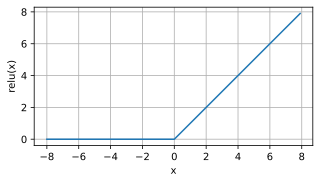

In [3]:
x = torch.arange(-8.0, 8.0, 0.1, requires_grad=True)
y = torch.relu(x)
d2l.plot(x.detach(), y.detach(), 'x', 'relu(x)', figsize=(5, 2.5))

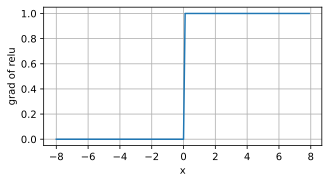

In [4]:
y.backward(torch.ones_like(x), retain_graph=True)
d2l.plot(x.detach(), x.grad, 'x', 'grad of relu', figsize=(5, 2.5))

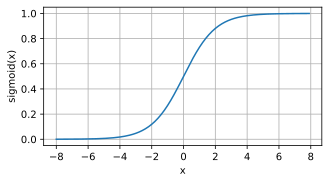

In [5]:
y = torch.sigmoid(x)
d2l.plot(x.detach(), y.detach(), 'x', 'sigmoid(x)', figsize=(5, 2.5))

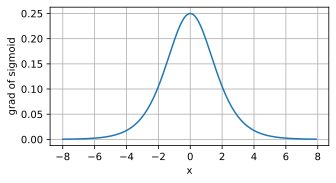

In [6]:
# Clear out previous gradients
x.grad.data.zero_()
y.backward(torch.ones_like(x),retain_graph=True)
d2l.plot(x.detach(), x.grad, 'x', 'grad of sigmoid', figsize=(5, 2.5))

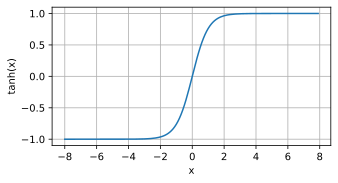

In [9]:
y = torch.tanh(x)
d2l.plot(x.detach(), y.detach(), 'x', 'tanh(x)', figsize=(5, 2.5))

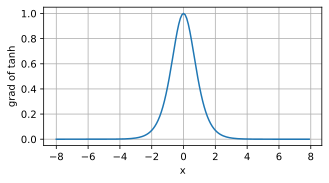

In [10]:
# Clear out previous gradients
x.grad.data.zero_()
y.backward(torch.ones_like(x),retain_graph=True)
d2l.plot(x.detach(), x.grad, 'x', 'grad of tanh', figsize=(5, 2.5))

### 5.1.3 Summary and Discussion
* Nonlinearities enable MLPs to become more complex
* Other alternatives to ReLU, pReLU, Sigmoid, tanh mentioned here. There is also the Gaussian Error Linear Unit (GELU) and Swich Activation function: $ \sigma(x) = x \text{ sigmoid}(\Beta x)$

### 5.1.4 Exercises
1. Show that adding layers to a *linear* deep network, i.e., a network without
   nonlinearity $\sigma$ can never increase the expressive power of the network.
   Give an example where it actively reduces it.
1. Compute the derivative of the pReLU activation function.
1. Compute the derivative of the Swish activation function $x \operatorname{sigmoid}(\beta x)$.
1. Show that an MLP using only ReLU (or pReLU) constructs a
   continuous piecewise linear function.
1. Sigmoid and tanh are very similar.
    1. Show that $\operatorname{tanh}(x) + 1 = 2 \operatorname{sigmoid}(2x)$.
    1. Prove that the function classes parametrized by both nonlinearities are identical. Hint: affine layers have bias terms, too.
1. Assume that we have a nonlinearity that applies to one minibatch at a time, such as the batch normalization. What kinds of problems do you expect this to cause?
1. Provide an example where the gradients vanish for the sigmoid activation function.

Exercise #1

Suppose we have a linear-only deep network with biases so:
$$h_1 = W_1 x + b_1, h_2 = W_2 h_1 + b2, \cdots , y = W_n h_{n-1} +b_n$$

Substituting the expression for $h_1$ into $h_2$, we get: 
$$ h_2 = W_2 (W_1 x + b_1) + b2 = W_2 W_1 x + W_2 b_1 + b_2$$

We see that if we were to continue this, we would just end up with an expression that can be collapsed into:
$$ y = W_{eff} x + b_{eff} $$

An example of a linear deep network that decreases the expressive power is where we use a single higgen linear layer consisting of only 1 neuron in a linear mapping between $\mathbb{R}^{2 \times 2} \rightarrow \mathbb{R}^{2 \times 2}$. We will also assume no biases for convienece. 

This would make it: $h_1 = W_1 x$ and $y = W_2 h_1$ where as assume $W_1 = \begin{bmatrix} a & b\end{bmatrix}$ and $W_2 = \begin{bmatrix}c \\d \end{bmatrix}$. Substituting the expressions, we get: $W_{eff} = W_2 W_1 = \begin{bmatrix} ac & bc \\ ad & bd \end{bmatrix}$. We see that the $W_{eff}$ matrix has rank 1 due to column 1 being linearly dependent on column 2. This decreases its expressive power for a $\mathbb{R}^{2 \times 2} \rightarrow \mathbb{R}^{2 \times 2}$ mapping. 

Exercise #2

$\text{pReLU}(x) = \text{max}(0, x) + \alpha \text{min}(0, x) = \begin{cases} x \text{ if } x>0 \\ \alpha x \text{ if } x \leq 0 \end{cases}$

Taking the derivative of this, we get: a derivative of $1$ for $x>0$, and a derivative of $\alpha$ for $x \leq 0$. 

Exercise #3

$$
\text{swish}(x)=x\text{ sigmoid}(\beta x)=\frac{x}{1+e^{-\beta x}}
$$

$$
\text{swish}'(x)=\text{ sigmoid}(\beta x) \left( 1 + \beta x e^{-\beta x} \text{ sigmoid}(\beta x) \right)
$$

Exercise #4

# I DON'T KNOW HOW TO DO THIS PROOF. COME BACK LATER

Exercise #5

1. Show that $\operatorname{tanh}(x) + 1 = 2 \operatorname{sigmoid}(2x)$.
    * LHS: $\text{tanh}(x) + 1 = \frac{1 - \exp{(-2x)}}{1 + \exp{(-2x)}} + \frac{1 + \exp{(-2x)}}{1 + \exp{(-2x)}} = \frac{2}{1 + \exp{(-2x)}}$
    * RHS: $2 \text{ sigmoid}(2x) = \frac{2}{1+\exp{(-2x)}} $
1. Prove function classes parametrized by both nonlinearties are identical. Hint: Affine layers have bias terms, too.  
# I DON'T KNOW HOW TO DO THIS PROOF. COME BACK LATER

Exercise #6

Some problems that can arise from minibatch-level nonlinearities is that at inferece, it is possible that inputs are being processed 1 at a time, and hence batch norm is difficult to run at inference. Once can choose to freeze the batchnorm process from training data, but there is no garuntee that the batchnorm from training will be reasonable for every sample at inference. 

Exercise #7

Look at corresponding graph of derivative of sigmoid function above. If inputs into neuron are too large or small in magnitude, then the gradient will disappear. 

# 5.2 Implementation of Multilayer Perceptrons

In [11]:
import torch
from torch import nn
from d2l import torch as d2l

### 5.2.1 Implementation from Scratch

* Will flatten input into $28 \times 28 = 784$ vector. Hidden layer of $256$, and final classification of 10 classes
* Both number of layers and width of each layer are adjustable hyperparameters
* Typically choose layer widths of powers of 2 since this is computationally efficient in terms of memory
* For every layer, we must keep track of one weight matrix and one bias vector. Memory for gradients of loss for each parameter needs to be allocated asw
* Below, we will call the nn.Parameter class to ensure they can be tracked by _autograd_ 

* Note, the training loop for MLPs is exactly the same as softmax regression where we call instances of the model, data, trainer and then call the _fit_ method of the trainer on the model and data instances

In [13]:
def relu(X):
    a = torch.zeros_like(X)  # Create a tensor of zeros of same size as input tensor
    return torch.max(X, a)   # Elementwise max of zero tensor and input tensor

class MLPScratch(d2l.Classifier):
    def __init__(self, num_inputs, num_outputs, num_hiddens, lr, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.W1 = nn.Parameter(torch.randn(num_inputs, num_hiddens) * sigma)
        self.b1 = nn.Parameter(torch.zeros(num_hiddens))
        self.W2 = nn.Parameter(torch.randn(num_hiddens, num_outputs) * sigma)
        self.b2 = nn.Parameter(torch.zeros(num_outputs))

    def forward(self, X):
        X = X.reshape( (-1, self.num_inputs) )      # Reshape to (batch_size, num_inputs)
        H = relu( torch.matmul(X, self.W1) + self.b1 )
        return torch.matmul(H, self.W2) + self.b2

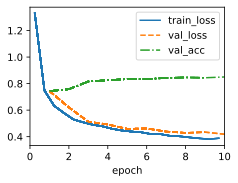

In [14]:
model = MLPScratch(num_inputs=784, num_outputs=10, num_hiddens=256, lr=0.1)
data = d2l.FashionMNIST(batch_size=256)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

### 5.2.2 Concise Implementation
* With high-level API
* Previously in scratch implementation, a _forward_ method was defined for the MLP class. It is not here, because the MLP with the API (implemented below) will inherit from the d2l.Classifier (which itself inherits from the Module) class, which already has a _forward_ method defined that just returns _self.net(X)_ (Check here: https://github.com/d2l-ai/d2l-en/blob/master/d2l/torch.py#L179) which is now defined as a series of sequence of transformations using the _nn.Sequential_ class
    * How the _nn.Sequential_ class works will be discussed more in detail in Section 6.1.2

In [15]:
class MLP(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(nn.Flatten(), nn.LazyLinear(num_hiddens),
                                 nn.ReLU(), nn.LazyLinear(num_outputs))

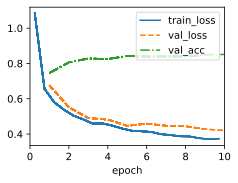

In [16]:
model = MLP(num_outputs=10, num_hiddens=256, lr=0.1)
trainer.fit(model, data)

### 5.2.3 Summary

* Can reuse training algo and data loader when designing neural networks
* Note how implementing MLPs and neural networks from scratch si messy due to naming and keeping track of different model params
    * Doing it from scratch also makes it difficult to perform meaningful performance optimizations

### 5.2.4 Exercises

1. Change the number of hidden units `num_hiddens` and plot how its number affects the accuracy of the model. What is the best value of this hyperparameter?
1. Try adding a hidden layer to see how it affects the results.
1. Why is it a bad idea to insert a hidden layer with a single neuron? What could go wrong?
1. How does changing the learning rate alter your results? With all other parameters fixed, which learning rate gives you the best results? How does this relate to the number of epochs?
1. Let's optimize over all hyperparameters jointly, i.e., learning rate, number of epochs, number of hidden layers, and number of hidden units per layer.
    1. What is the best result you can get by optimizing over all of them?
    1. Why it is much more challenging to deal with multiple hyperparameters?
    1. Describe an efficient strategy for optimizing over multiple parameters jointly.
1. Compare the speed of the framework and the from-scratch implementation for a challenging problem. How does it change with the complexity of the network?
1. Measure the speed of tensor--matrix multiplications for well-aligned and misaligned matrices. For instance, test for matrices with dimension 1024, 1025, 1026, 1028, and 1032.
    1. How does this change between GPUs and CPUs?
    1. Determine the memory bus width of your CPU and GPU.
1. Try out different activation functions. Which one works best?
1. Is there a difference between weight initializations of the network? Does it matter?

Exercise #1

Varying the _num_hiddens_ at values 62, 256, 1024, it is found that they seem to have roughly the same training loss, validation loss, and validation accuracy. No meaningful/drastic differences between the 3 values tested. 

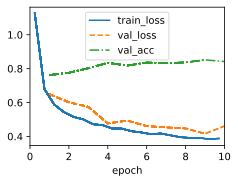

In [17]:
class MLP_H64(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(nn.Flatten(), nn.LazyLinear(num_hiddens),
                                 nn.ReLU(), nn.LazyLinear(num_outputs))
        
model_64 = MLP_H64(num_outputs=10, num_hiddens=64, lr=0.1)
trainer.fit(model_64, data)

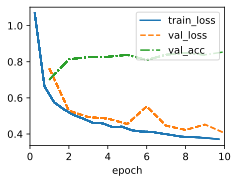

In [18]:
class MLP_H256(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(nn.Flatten(), nn.LazyLinear(num_hiddens),
                                 nn.ReLU(), nn.LazyLinear(num_outputs))
        
model_256 = MLP_H256(num_outputs=10, num_hiddens=256, lr=0.1)
trainer.fit(model_256, data)

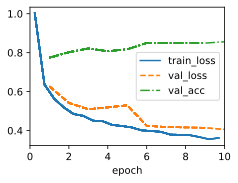

In [19]:
class MLP_H1024(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(nn.Flatten(), nn.LazyLinear(num_hiddens),
                                 nn.ReLU(), nn.LazyLinear(num_outputs))
        
model_1024 = MLP_H1024(num_outputs=10, num_hiddens=1024, lr=0.1)
trainer.fit(model_1024, data)

Exercise #2

Added another hidden layer of same same dimension (256) just below. Does not seem to meaningfully change the final training loss, validation loss, nor the validation accuracy.  

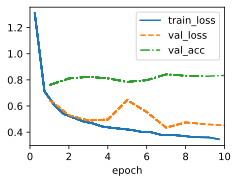

In [20]:
class MLP_TwoHidden256(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(nn.Flatten(), 
                                 nn.LazyLinear(num_hiddens), nn.ReLU(), 
                                 nn.LazyLinear(num_hiddens), nn.ReLU(),
                                 nn.LazyLinear(num_outputs))
        
model_TwoHidden256 = MLP_TwoHidden256(num_outputs=10, num_hiddens=256, lr=0.1)
trainer.fit(model_TwoHidden256, data)

Exercise #3

It is a bad idea to insert a hidden layer with a single neuron since mathematically it decreases your overall expressive power of the network (see earlier exercise from 5.1). See below an example of it, the empirical results are clearly bad w.r.t. not using a single-neuron hidden layer

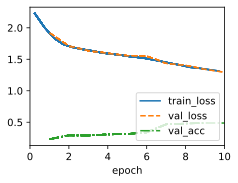

In [21]:
class MLP_HiddenNeuron(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(nn.Flatten(), 
                                 nn.LazyLinear(num_hiddens), nn.ReLU(), 
                                 nn.LazyLinear(1), nn.ReLU(),
                                 nn.LazyLinear(num_outputs))
        
model_HiddenNeuron = MLP_HiddenNeuron(num_outputs=10, num_hiddens=256, lr=0.1)
trainer.fit(model_HiddenNeuron, data)

Exercise #4 

Varying the learning rate between 0.01, 0.1, 1.0, it is found that lr=0.01 converges much slower than the default previous of 0.1, but it is much more stable since the 3 curves tracked are quite smooth in their descent/ascent. 

w.r.t. to the number of epochs, a smaller learning rate would require a larger number of epochs, as shown in the lr=0.01 example where the train/val loss is still above 0.5 at the 10th epoch, compared to the 0.1 learning rate where both train/val loss are around 0.4. 

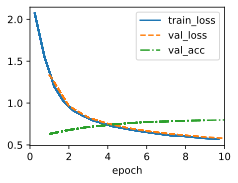

In [22]:
model = MLP(num_outputs=10, num_hiddens=256, lr=0.01)
trainer.fit(model, data)

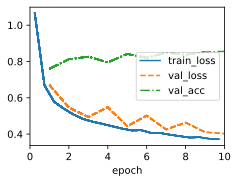

In [23]:
model = MLP(num_outputs=10, num_hiddens=256, lr=0.1)
trainer.fit(model, data)

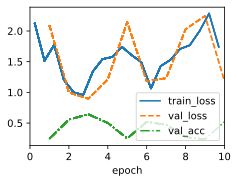

In [24]:
model = MLP(num_outputs=10, num_hiddens=256, lr=1.0)
trainer.fit(model, data)

Exercise #5

1. Best result of the hyperparameter combination test was: N/A. I didn't run the whole thing because it would take too long and not be particuarly insightful. Plus I wrote the hyperparameter sweep with Claude...
1. It is challenging to deal with multiple hyperparameters because the number of combinations you need to test explodes with number of hyperparameters and values of hyperparameter one wants to test. It will also take a lot of time and resouces to run the comprehensive sweep. 
1. An efficient strategy optimize over joint hyperparameters should be just to sweep each hyperparameter one at a time to find the optimal value, and assume said optimal value will hold for the final network. 

In [25]:
epoch_nums     = [5, 10, 15, 20]
learning_rates = [0.01, 0.05, 0.1, 1.0]
hidden_neurons = [64, 256, 1024]
hidden_layers  = [1, 2, 3]



In [1]:
# I used Claude for this below
import itertools
import time
import pandas as pd
import torch
from torch import nn
from d2l import torch as d2l

# ── Flexible MLP: variable depth and width ────────────────────────────────────
class FlexMLP(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens, num_layers, lr):
        super().__init__()
        self.save_hyperparameters()
        layers = [nn.Flatten()]
        for _ in range(num_layers):
            layers += [nn.LazyLinear(num_hiddens), nn.ReLU()]
        layers.append(nn.LazyLinear(num_outputs))
        self.net = nn.Sequential(*layers)

# ── Silent board: stores metrics without rendering plots ──────────────────────
class SilentBoard:
    def __init__(self):
        self.data = {}
    def draw(self, x, y, label, every_n=1):
        if label not in self.data:
            self.data[label] = []
        self.data[label].append((x, float(y)))

class SilentTrainer(d2l.Trainer):
    def prepare_model(self, model):
        model.trainer = self
        model.board = SilentBoard()
        self.model = model

# ── Hyperparameter grid ───────────────────────────────────────────────────────
epoch_nums     = [5, 10, 20]
learning_rates = [0.01, 0.1, 1.0]
hidden_neurons = [64, 256, 1024]
hidden_layers  = [1, 2, 3]

data   = d2l.FashionMNIST(batch_size=256)
combos = list(itertools.product(epoch_nums, learning_rates, hidden_neurons, hidden_layers))
results = []

print(f"Running {len(combos)} experiments...\n")
sweep_start = time.time()

for i, (epochs, lr, neurons, layers) in enumerate(combos, 1):
    t0 = time.time()

    model   = FlexMLP(num_outputs=10, num_hiddens=neurons, num_layers=layers, lr=lr)
    trainer = SilentTrainer(max_epochs=epochs)
    trainer.fit(model, data)

    board    = model.board.data
    val_acc  = board.get('val_acc',  [(0, 0.0)])[-1][1]
    val_loss = board.get('val_loss', [(0, float('inf'))])[-1][1]
    elapsed  = time.time() - t0

    results.append(dict(epochs=epochs, lr=lr, neurons=neurons, layers=layers,
                        val_acc=round(val_acc, 4), val_loss=round(val_loss, 4)))

    print(f"[{i:3d}/{len(combos)}] ep={epochs:2d}  lr={lr:.2f}  neurons={neurons:4d}  layers={layers}"
          f"  →  val_acc={val_acc:.4f}  val_loss={val_loss:.4f}  ({elapsed:.1f}s)")

total_time = time.time() - sweep_start
print(f"\nTotal sweep time: {total_time/60:.1f} min")

# ── Results ───────────────────────────────────────────────────────────────────
df   = pd.DataFrame(results).sort_values('val_acc', ascending=False).reset_index(drop=True)
best = df.iloc[0]

print("\n=== Top 10 Configurations by Validation Accuracy ===")
print(df.head(10).to_string(index=False))
print(f"\nBest config:  epochs={int(best.epochs)},  lr={best.lr},  "
      f"neurons={int(best.neurons)},  layers={int(best.layers)}"
      f"  →  val_acc={best.val_acc:.4f},  val_loss={best.val_loss:.4f}")

Running 81 experiments...



c:\Users\jimmy\anaconda3\envs\d2l\lib\site-packages\torch\nn\modules\lazy.py:180: UserWarning: Lazy modules are a new feature under heavy development so changes to the API or functionality can happen at any moment.
  warnings.warn('Lazy modules are a new feature under heavy development '


[  1/81] ep= 5  lr=0.01  neurons=  64  layers=1  →  val_acc=0.8125  val_loss=0.5386  (21.0s)
[  2/81] ep= 5  lr=0.01  neurons=  64  layers=2  →  val_acc=0.7500  val_loss=0.6367  (21.1s)
[  3/81] ep= 5  lr=0.01  neurons=  64  layers=3  →  val_acc=0.6875  val_loss=0.7949  (20.8s)
[  4/81] ep= 5  lr=0.01  neurons= 256  layers=1  →  val_acc=0.8750  val_loss=0.4836  (21.0s)


KeyboardInterrupt: 

Exercise #6

Made network more complex, with 1024 neuron per hidden layer, with 3 hidden layers. Learning rate of 0.1 and 10 epochs. Note that the training time for API based MLP is less. Difference would probably be larger if I was using GPU, since I am running everything on CPU ATM. Difference would probably be more drastic as network gets more complex asw. 

Training time for complex MLP: 93.18 seconds


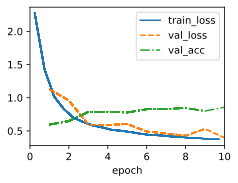

In [5]:
import time

def relu(X):
    a = torch.zeros_like(X)
    return torch.max(X, a)

class MLPScratchComplex(d2l.Classifier):
    def __init__(self, num_inputs, num_outputs, num_hiddens, lr, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.W1 = nn.Parameter(torch.randn(num_inputs, num_hiddens) * sigma)
        self.b1 = nn.Parameter(torch.zeros(num_hiddens))
        self.W2 = nn.Parameter(torch.randn(num_hiddens, num_hiddens) * sigma)
        self.b2 = nn.Parameter(torch.zeros(num_hiddens))
        self.W3 = nn.Parameter(torch.randn(num_hiddens, num_hiddens) * sigma)
        self.b3 = nn.Parameter(torch.zeros(num_hiddens))
        self.W4 = nn.Parameter(torch.randn(num_hiddens, num_outputs) * sigma)
        self.b4 = nn.Parameter(torch.zeros(num_outputs))
    
    def forward(self, X):
        X = X.reshape( (-1, self.num_inputs) )     
        H1 = relu( torch.matmul(X, self.W1) + self.b1 )
        H2 = relu( torch.matmul(H1, self.W2) + self.b2 )
        H3 = relu( torch.matmul(H2, self.W3) + self.b3 )
        return torch.matmul(H3, self.W4) + self.b4

start = time.perf_counter()
MLPScratchComplex = MLPScratchComplex(num_inputs=784, num_outputs=10, num_hiddens=1024, lr=0.1)
data = d2l.FashionMNIST(batch_size=256)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(MLPScratchComplex, data)
end = time.perf_counter()
print(f"Training time for complex MLP: {end - start:.2f} seconds")

Training time for complex concise MLP: 72.44 seconds


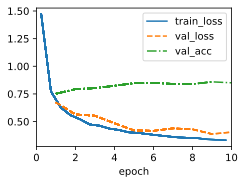

In [6]:
import time

class MLPComplex(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(nn.Flatten(), 
                                 nn.LazyLinear(num_hiddens), nn.ReLU(), 
                                 nn.LazyLinear(num_hiddens), nn.ReLU(),
                                 nn.LazyLinear(num_hiddens), nn.ReLU(),                                
                                 nn.LazyLinear(num_outputs))
        
start = time.perf_counter()
MLPComplex = MLPComplex(num_outputs=10, num_hiddens=1024, lr=0.1)
data = d2l.FashionMNIST(batch_size=256)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(MLPComplex, data)
end = time.perf_counter()
print(f"Training time for complex concise MLP: {end - start:.2f} seconds")

Exercise #7

# COME BACK LATER AND DO IT EMPRICIALLY. NOT IN THE MOOD RN. Dosen't seem particuarly insightful asw. I'll take the textbook's word for it for now. 

Exercise #8

# COME BACK LATER AND DO IT EMPRICIALLY. NOT IN THE MOOD RN. Dosen't seem particuarly insightful asw. I'll take the textbook's word for it for now.  

Exercise #9

Yes, typically the weigh initializations are quite important and will change the training run qualities. 

# COME BACK LATER AND DO IT EMPRICIALLY. NOT IN THE MOOD RN. Dosen't seem particuarly insightful asw. I'll take the textbook's word for it for now. 

# 5.3 Forward Propagation, Backward Propagation, and Computational Graphs

### 5.3.1 Forward Propogation

* Advance from inputs/features through the layers of the network. 
* Objective functino is: Loss Function + Regularization Term

### 5.3.2 Computational Graph of Forward Propogation
See figure in textbook

### 5.3.3 Backpropagation
IK how this works

### 5.3.4 Training Neural Networks

* During forward pass, traverse computational graph in direction of dependencesi and compute all variables along path
* During backwards pass, the compute order on the computational graph is reversed
* Once model parameters are initialized, we alternate between forward and backwards passes, updating learnable parameters using gradients received from backprop
* Note taht backprop reuses stored intermediate values from forward pass to avoid duplicate calculations. This means that we must retain all intermediate values until the backwards pass is complete
    * Thus, this is why training requires much more memroy than plain prediction (running the model)
    * Size of intermediate values is proportional to number of network layers and batch size - thus training deeper networks with large batch sizes is more prone to out-of-memory errors

### 5.3.5 Summary
See above

### 5.3.6 Exercises

1. Assume that the inputs $\mathbf{X}$ to some scalar function $f$ are $n \times m$ matrices. What is the dimensionality of the gradient of $f$ with respect to $\mathbf{X}$?
1. Add a bias to the hidden layer of the model described in this section (you do not need to include bias in the regularization term).
    1. Draw the corresponding computational graph.
    1. Derive the forward and backward propagation equations.
1. Compute the memory footprint for training and prediction in the model described in this section.
1. Assume that you want to compute second derivatives. What happens to the computational graph? How long do you expect the calculation to take?
1. Assume that the computational graph is too large for your GPU.
    1. Can you partition it over more than one GPU?
    1. What are the advantages and disadvantages over training on a smaller minibatch?

Exercise #1 

The dimensionality of the gradient will be $n \times m$. Each element of gradient matrix wll just be the derivative of the output scalar w.r.t. to the parameter corresponding to the index of the matrix. 

Exercise #2

On paper. 

Exercise #3

Skip. 

Exercise #4

To calculate the full 2nd derivative (i.e. Hessian), the matrix would be $ (nm) \times (nm)$. This is because every element of the first derivative needs to be differentiated again, w.r.t. the matrix elements again. The computation graph grows since need to track 2nd order gradients asw (instead of just the first). This will take a significantly longer amount of time than just the 1st order gradients. 

Exercise #5

1. Yes, it is possible to partition it over more than 1 GPU. Say, group layer(s) by GPUs, does hidden layers 1-3 on GPU1, 4-6 on GPU2, etc.
1. Smaller minibatch
    * Advantages:    Reduces memory usage
    * Disadvantages: Minibatch gradient updates becomes more "noiser" since they are less representative of the entire training set they are meant to represent. THey could also underutilize available computing resources (while memory is saved)

# 5.4 Numerical Stability and Initialization

Poor choices can result in vanishing/exploding gradient problems if design choices are not properly considered (random weight initialization, etc. )

### 5.4.1 Vanishing and Exploding Gradients
* Activation function may exacerbate vanishing gradient problem 
* Historically, sigmoids were popular because of their biological plausibility of firing entirely (1), or not at all (0). 
* Take a look at why sigmoids cause vanishing gradient problem 
    * Unless we are in the goldilock zone of inputs close to 0, the gradient will be suppressed. It is likely in a deep neural network, the gradient signal flowing back from the loss will be cut off at some layer
    * ReLUs are more stable (but less biologically plausible) and have thus emerged as default choice (apparently) iirc GELU's are popular...
* Take a look at exploding gradient problem
    * If variance/std of random weight initalization is too large, the matrix product explodes during the forward pass, especially for deeper neural networks.
    * Cause serious difficulty in getting SGD to converge

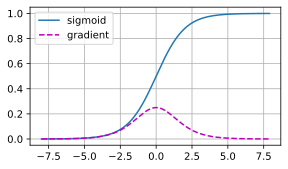

In [ ]:
# Vanishing Gradient Demo
x = torch.arange(-8.0, 8.0, 0.1, requires_grad=True)
y = torch.sigmoid(x)
y.backward(torch.ones_like(x))

d2l.plot(x.detach().numpy(), [y.detach().numpy(), x.grad.numpy()],
         legend=['sigmoid', 'gradient'], figsize=(4.5, 2.5))

In [12]:
M = torch.normal(0, 1, size=(4, 4))
print('a single matrix \n',M)
for i in range(100):
    M = M @ torch.normal(0, 1, size=(4, 4))
print('after multiplying 100 matrices\n', M)

a single matrix 
 tensor([[-1.6327, -0.9038,  0.7635, -0.2928],
        [-0.4228, -0.7337,  0.7519, -0.6825],
        [ 0.3070, -1.8585,  0.1535,  1.9141],
        [-2.2940, -0.9166,  0.7671,  0.4660]])
after multiplying 100 matrices
 tensor([[3.2834e+22, 2.5184e+23, 7.6353e+22, 5.4056e+21],
        [4.1371e+21, 3.1731e+22, 9.6203e+21, 6.8109e+20],
        [3.1260e+22, 2.3977e+23, 7.2693e+22, 5.1464e+21],
        [6.0400e+22, 4.6327e+23, 1.4046e+23, 9.9438e+21]])


Symmetry in neural network parametrization
* Supposed we have a MLP with one hidden layer and 2 units
    * We cuold permute weights of weights of weights of first layer (hidden) and the corresponding output layer to obtain the overall same function of the neural network - a form of permutation symmetry among the hidden units of each layer
    * Q: Why does this matter?
    * A: Suppose extreme, hypothetical case of hidden layer where all parameters of a hiddne layer are initiliazed to the same value. Backprop, differentiatin ghte output w.r.t. parameters would give a gradient update of parameters that is all the sameupdate, and thus minibatch SGD would not break the symmetry here. Note, it is possible to break the symmetry using *dropout*, which helps to realize the full expressive power of the network (and also apparently is 'balanced out' the network's circuits and discourages concentrating on a few learned patterns)

In [ ]:
# Enabled GPU Utilization 
import torch
torch.cuda.is_available()

True

In [3]:
torch.__version__

'2.8.0+cu126'

### 5.4.2 Parameter Initialization
* One way of mitigating/addrssing issue above is through careful initializatino of parameters. Additional methods will be presented later for more optimizatio nand suitable regularizaiton. 

By Default - Normal Distribution Initializaiton 
* Normal distribution to initialize weight values. If no other method is specified, the framework/API will default to this which is fine for moderate problem sizes

Xavier Initialization
*  Consider the distribution of output $o_i$ for some fully-connected layer _without nonlinearties_, where there are $n_{in}$ inputs $x_j$ with corresponding weights of $w_{ij}$. An output for this layer is given by:
$$ o_i = \sum_{j=1}^{n_{in}} w_{ij} x_j $$
* Weights $w_{ij}$ are drawn from the same distribution of mean $ = \mu = 0$ and variance $\sigma^2$. (distribution is not necessarily gaussian, just has a defined mean and variance)
* For now, assume that inputs $x_j$ have mean $ = \mu = 0$ and variance $\gamma^2$. 
* Inputs $x_{ij}$ are independent of the weights $w_{ij}$
* We can compute the mean of $o_i$ where we recall that $x_j$ and $w_{ij}$ are independent of one another, and thus can be factored:
$$E[o_i] = \sum_{j=1}^{n_{in}} E[w_{ij} x_k] = \sum_{j=1}^{n_{in}} E[w_{ij}] E[x_k] = 0$$
* The variance of the output can be calculated as follows, again keeping in mind that x_j$ and $w_{ij}$ are independent of one another:
$$ \text{Var}[o_i] = E[o_i^2] - (E[o_i])^2 = \sum_{j=1}^{n_{in}} E[w_{ij}^2 x_j^2] - 0 = \sum_{j=1}^{n_{in}} E[w_{ij}^] E[x_j^2] = n_{in} \sigma^2 \gamma^2 $$
* One way to keep the variance fixed is to set: $n_{in} \sigma^2 = 1$ for the forward pass
* Following same logic for the backwards pass, we get: $n_{out}\sigma^2 = 1$. 
* These two conditions cannot be always satisfied unless $n_{out} = n_{in}$, which cannot be garunteed. 
* We settle and try to satify: 
$$\frac{1}{2}(n_{in}+n_{out})\sigma^2 = 1 \text{ or equivalently } \sigma = \sqrt{\frac{2}{n_{in} + n_{out}}}$$
* Thus, Xavier initialization will sample weights from a Gaussian distribution of zero mean and variance $ \sigma^2 = \frac{2}{n_{in} + n_{out}}$. Recall we assumed no non-linearities when deriving the Xavier initialization restrictions, but in practice in neural networks with non-linearities, it works fine. 
* It is also possible to adapt Xavier initializatino for uniform distributions from $-a, a$. Recall the uniform distributions have variance $a^2 / 3$ and plugging that into our condition we get a uniform distribution from $-\sqrt{\frac{6}{n_{in} + n_{out}}}, \sqrt{\frac{6}{n_{in} + n_{out}}}$

### 5.4.3 Summary

Deep learning frameworks have dozen different heuristics for parameter initialization. Main other one seems to be Kaiming initalization. See here for PyTorch: https://docs.pytorch.org/docs/2.12/nn.init.html

### 5.4.4 Exercises

1. Can you design other cases where a neural network might exhibit symmetry that needs breaking, besides the permutation symmetry in an MLP's layers?
1. Can we initialize all weight parameters in linear regression or in softmax regression to the same value?
1. Look up analytic bounds on the eigenvalues of the product of two matrices. What does this tell you about ensuring that gradients are well conditioned?
1. If we know that some terms diverge, can we fix this after the fact? Look at the paper on layerwise adaptive rate scaling  for inspiration You.Gitman.Ginsburg.2017.

Exercise #1
* All weights & biases for a hidden MLP layer initialized to 0
* Blind/naive attention mechanism. No positional encoding. 

Exercise #2

For linear regression, yes it is fine to initialize weight parameters to the same value. 

Consider a linear regression with 2 features and weights: 
$$ \hat{y} = w_1 x_1 + w_2 x_2 + b$$
If we were to initialize $w_1 = w_2$, this is not a big deal as the gradient updates they receive are dependent on the input features, not the weight values themselves: $\frac{\partial \ell}{\partial w_1} = x_1$, $\frac{\partial \ell}{\partial w_2} = x_2$, and thus the symmetry is broken

Logic for softmax is that gradient signal received from the correct class will by design be different than the gradient loss signals received from all other classes (incorrect ones)

Exercise #3

Analytical Bound on eigenvalues of product of 2 matricies: https://math.stackexchange.com/questions/1193763/eigenvalues-of-product-matrix

Both the largest and smallest eigenvalues should be as close to 1 as possible to prevent gradient explosion/suppression for deep neural networks. 

Eigenvalues represent how stretched/compressed eigenvectors become when a matrix multiplication is done to said eigenvector. We don't want the backprop gradient signals to be stretched/compressed as they are passing through Jacobians of the layers of the neural network (matrix operations), so want to keep eigenvalues close to 1 as possible. 


Exercise #4 

Reccomended paper is Layerwise Adaptive Rate Scaling (LARS) 2017 paper. Read in detail later. General idea seems to be change the learning rate based on the norms of the weights and norms of gradients for more stable training. 

Adaptive learning rate adjustments would help counter the effect of vanishing/exploding gradients by still allowing gradient signals to have an effect. 

# 5.5. Generalization in Deep Learning

* Fitting training data was only intermediate goal. Real goal is to discover general patterns that can be used to make accurate predictions on new samples from same underlying population 
* ML is a _consumer_ of optimization algorithms, and in some cases must develop them 
    * Keep in mind optimization is only a means to an end
* Empirically, SGD trained models generalize well across CV, NLP, time series data, reccomended system, etc. Why resulting models generalize to unseen examples is unknown 
* Even absent the comfort of a coherent scientific theory, practitioners have developed a large collection of techniques that may help you to produce models that generalize well in practice
* Following sectin is to present broad overview of state of research & practice

### 5.5.1 Revisiting Overfitting and Regularization

* "No Free Lunch" Theorem 1995, any learning algorithm generalizes better on data with certain distributions and worse with other distributions
    * Given a finite training set, a model relies on certain assumoptions
    * To achieve human-level performance it may be useful to identify _inductive biases_ that reflect how humans think about the world that show preferences for solutions with certain properties
    * e.g. Deep MLP has inductive bias towards building a complicated function by composition of simpler ones
* Classification problems - models are expressive enough to perfectly fit every training example, even datasets in the millions
* We may think any improvements to generalization must come by regularization by either reducing complexity of model class or applying a penalty, or by constraining values parameters can take
* When generalizaton gap is large, we may say that the model overfit to the training data. Classical theory states that our models are too complex, requiring we shrink our feature found, the number of nonzero parameters learned, or size of parameters. 
* However in practice for deep learning, we can decrease generalization error by making model even more expressive (adding layers, nodes, more epochs)
* "Double-Descent" where greater complexity hurts at first, but with even greater complexity, fits training data and generalizes better (non monotonic function)
* Since deep neural networks are capable of fitting arbitrary labels even for large datasets, despite use of $\ell_2$ regularization or traditional complexity based generalization bounds (VC-dimension, Rademacher complexity) cannot explain why neural nets generalize

### 5.5.2 Inspiration from Nonparametrics

* Tempting to think of deep learning as parametreic models (learnable parameters that are updated)
* While neural networks clearly have parameters, it may be more fruitful to think of them as behaving like non-parametric models
    * Q: What determines parametric/non-parametric?
    * A: Non-parametric methods tend to have a level of complexity that grows as amount of available data grows
* e.g. K-nearest neighbors that just memorize dataset and at prediction time, just looks up closest data point. 
* Neural networks are overparameterized (more parameters needed to fit training data) so they end up interpolating the training data (i.e. fit it perfectly) and in a way behave like non-parametric models 
* Jacot et. al. 2018 paper that shows in limit, MLP w/ randomly initialized weights grow infinityly wide and become equivalent to (non-parametric) kernel methods for a specific choice of kernel function (distance function) which they call the neural tangent kernel

### 5.5.3 Early Stopping

* Check Word Doc for more details for papers (or webpage itself)
    * Deep neural netwrosk can fit arbitrary labels, even when labels are assigned incorrectly/randomly (only emerges after many iterations of training)
    * Under label noise, nerual networks fit labeled data cfirst, then interpolate the mislabeled data
    * The phenomena just above (fit cleanly labeled data but not randomly labeled examples in training set), it has in fact generalized

* _Early Stopping_: Constrain number of epochs in training
    * Monitor validation error throughout trianing (usually once after each epoch)
    * If validaion error has not decreased by more than an amount $\epsilon$ for a specified number of epochs, terminate training
    * a.k.a. "patience criterion"
    * Can help with generalization, but also practical concern of compute resources & time
* NOTE: When there is no label noise and datasets are realizable (i.e. classes are truly separable, say cats from dogs), early stopping does not lead to notable improvements in generalizatoin. Only when labels are noisy, or data itself is onisy (e.g. predicting mortality in patients). Training these models till interpolation is typically a bad idea

### 5.5.4 Classical Regularization Methods for Deep Networks

* Weight decay is popular, but insufficient to prevent data interpolation
* Regularization might make sense in combinatio with early stopping
* Dropout mentioned, will be covered in next sectino 

### 5.5.5 Summary

* Although deep NN's are over-parameterized, may be helpful to thing of them as non-parametric models (for intuition purposes)
* Since DNN's are generally capable of fitting the entire training set, closing generalization gap comes from primarily preventing overfitting
* Some techniques to achieve this goal are counterintuitive, such as techniques that both increase and decrease model complexity having shown to help
* note - these methods can't be explained by classical theory about generalization  

### 5.5.6 Exercises

1. In what sense do traditional complexity-based measures fail to account for generalization of deep neural networks?
1. Why might *early stopping* be considered a regularization technique?
1. How do researchers typically determine the stopping criterion?
1. What important factor seems to differentiate cases when early stopping leads to big improvements in generalization?
1. Beyond generalization, describe another benefit of early stopping.

Exercise #1

Stuff like VC dimension or those error bounds or raw parameter count don't capture entire space of characteristics/properties that determine model performance (parameter initializtion, training techniques, training data distribution, inductive biases of the model, etc.)


Exercise #2

Prevents model from fitting noisy data to help it generalize, de-facto regularization 

Exercise #3

Probably heuristics/literature. Im assuming this is talking about the early-stopping criterion where the $\epsilon$ and # of epochs...

Exercise #4

Weather the dataset and labels are noisy and realizable (e.g. classes are truly separable). If that is not the case, early stopping would not help much (supposedly)

Exercise #5

Saves on compute time and resources/cost

# 5.6 Dropout

* Basically inject noise to the input during the training process
* Prevents network from becoming over-reliant on certain connections/"circuits"
* Want to keep the expectation of each layer/component the same, with and without said noise

Method #1: What Bishop 1995 did
* Add noise sampled from distribution centered at 0 to input $x$. Under expectation, they are still the same

Method #2: What is typically done in ML/DL
* Zeroes out a certain fraction of nodes in each layer and debiases each layer by normalizing by fraction of nodes that were retained
* Each intermiediate activation $h$ is replaced by random variable $h'$ as:
$$ h' = \begin{cases} 0 & \text{with probability p }  \\ \frac{h}{1-p} & \text{probability 1-p }  \end{cases}$$
* Random variable $h'$ is same under expectaiton operation
$$ E[h'] = (p)(0) + \frac{h}{1-p} (1-p) = h $$

### 5.6.1 Dropout in Practice

* Note, once certain neurons are removed, their respective gradient vanishes asw
     * Supposed to prevent layers from becoming over dependent on certain neurons/connections
* Dropout typically disabled at test time
* Sometimes, dropout is kept at test-time, to see if predictions agree across different dropout configs. Supposed to show NN confidence/robustness

### 5.6.2 Implementation from Scratch

In [31]:
def dropout_layer(X, dropout_prob):
    assert 0 <= dropout_prob <= 1
    if dropout_prob == 1: return torch.zeros_like(X)

    # Notice, rand, not randn so will draw uniformly from [0, 1)
    # mask is a tensor of 0s and 1s where 1s indicate keep elements. 0's are dropout
    mask = (torch.rand(X.shape) > dropout_prob).float()  
    return mask * X / (1.0 - dropout_prob) # Normalization of h to get h' 

In [32]:
# Test it out with dropout probs of 0, 0.5, and 1
X = torch.arange(16, dtype = torch.float32).reshape((2, 8))
print('dropout_p = 0:', dropout_layer(X, 0))
print('dropout_p = 0.5:', dropout_layer(X, 0.5))
print('dropout_p = 1:', dropout_layer(X, 1))

dropout_p = 0: tensor([[ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11., 12., 13., 14., 15.]])
dropout_p = 0.5: tensor([[ 0.,  2.,  4.,  0.,  8., 10.,  0.,  0.],
        [ 0.,  0., 20.,  0.,  0., 26.,  0., 30.]])
dropout_p = 1: tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]])


In [33]:
# MLP from scratch with dropout applied to each hidden layer AFTER the activation function. 
# dropout probability can be set for each layer separately. Typically smaller dropout probabilities
# are used for earlier layers 

# Note: Dropout applied during forward method, not in the NN structure itself (__init__)
# Note: NN layers not defined using self.net feature as before. Individual layers will be called
# from forward method

class DropoutMLPScratch(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens_1, num_hiddens_2,
                 dropout_1, dropout_2, lr):
        super().__init__()
        self.save_hyperparameters()
        self.lin1 = nn.LazyLinear(num_hiddens_1)
        self.lin2 = nn.LazyLinear(num_hiddens_2)
        self.lin3 = nn.LazyLinear(num_outputs)
        self.relu = nn.ReLU()

    def forward(self, X):
        H1 = self.relu(self.lin1(X.reshape((X.shape[0], -1))))
        if self.training:
            H1 = dropout_layer(H1, self.dropout_1)
        H2 = self.relu(self.lin2(H1))
        if self.training:
            H2 = dropout_layer(H2, self.dropout_2)
        return self.lin3(H2)
        

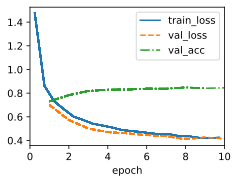

In [34]:
# Training

# Note: "**" is used to unpack dictionaries. Similar to '*' for iterables (lists, typles, strings, sets)

hparams = {'num_outputs':10, 'num_hiddens_1':256, 'num_hiddens_2':256,
           'dropout_1':0.5, 'dropout_2':0.5, 'lr':0.1}
model = DropoutMLPScratch(**hparams)
data = d2l.FashionMNIST(batch_size=256)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

### 5.6.3 Concise Implementation

Using d2l-PyTorch, Dropout layer is added after each fully connected layer with the only argument being the dropout probability. Will automatically turn on and off based on training mode or not (speciffied by model's mode)

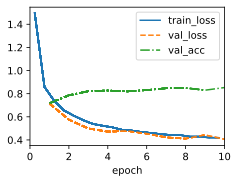

In [36]:
class DropoutMLP(d2l.Classifier):
    def __init__(self, num_outputs, num_hiddens_1, num_hiddens_2, 
                 dropout_1, dropout_2, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.Flatten(), nn.LazyLinear(num_hiddens_1), nn.ReLU(), 
            nn.Dropout(dropout_1), nn.LazyLinear(num_hiddens_2), nn.ReLU(),
            nn.Dropout(dropout_2), nn.LazyLinear(num_outputs)
        )

model = DropoutMLP(**hparams)
trainer.fit(model, data)

### 5.6.4 Summary

* Dropout is a tool use to avoid overfitting in conjunction with other tools
* Dropout is only used in training by replacing activation $h$ with the random variable $h'$ that is unbiased w.r.t. $h$

### 5.6.5 Exercises

1. What happens if you change the dropout probabilities for the first and second layers? In particular, what happens if you switch the ones for both layers? Design an experiment to answer these questions, describe your results quantitatively, and summarize the qualitative takeaways.
1. Increase the number of epochs and compare the results obtained when using dropout with those when not using it.
1. What is the variance of the activations in each hidden layer when dropout is and is not applied? Draw a plot to show how this quantity evolves over time for both models.
1. Why is dropout not typically used at test time?
1. Using the model in this section as an example, compare the effects of using dropout and weight decay. What happens when dropout and weight decay are used at the same time? Are the results additive? Are there diminished returns (or worse)? Do they cancel each other out?
1. What happens if we apply dropout to the individual weights of the weight matrix rather than the activations?
1. Invent another technique for injecting random noise at each layer that is different from the standard dropout technique. Can you develop a method that outperforms dropout on the Fashion-MNIST dataset (for a fixed architecture)?

Exercise #1

# 5.7 Predicting House Prices on Kaggle

### 5.7.1 Downloading Data

### 5.7.2 Kaggle

### 5.7.3 Accessing and Reading the Dataset

### 5.7.4 Data Preprocessing

### 5.7.5 Error Measure

### 5.7.6 K-Fold Cross-Validation

### 5.7.7. Model Selection

### 5.7.8 Submitting Predictions on Kaggle

### 5.7.9 Summary and Discussion

### 5.7.10. Exercises

1. Submit your predictions for this section to Kaggle. How good are they?
1. Is it always a good idea to replace missing values by a mean? Hint: can you construct a situation where the values are not missing at random?
1. Improve the score by tuning the hyperparameters through $K$-fold cross-validation.
1. Improve the score by improving the model (e.g., layers, weight decay, and dropout).
1. What happens if we do not standardize the continuous numerical features as we have done in this section?